This notebook is desigined to answer the question: "do nutritional profiles separate national cuisines, or do many cuisines collapse into a few nutritional profiles?"

# Notebook and Data Setup

In [1]:
# Load the libraries used in this notebook.
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the cleaned recipe data from the team repository and look at the first few
recipes_df = pd.read_csv('https://raw.githubusercontent.com/jalmendral/BA305-A1-TeamA2/main/Data/processed/recipes_clean.csv')
recipes_df.head()

,name,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,...,cook_time,total_time,servings,country,has_cuisine,year,nutrition_flag,time_flag,rating_missing,nutrition_missing
0,Chewy Whole Wheat Peanut Butter Brownies,https://www.allrecipes.com/recipe/140717/chewy...,DMOMMY,2020-06-18,"⅓ cup margarine, softened, ⅔ cup white sugar, ...",222.0,13.0,24.0,6.0,4.4,...,35.0,55.0,16.0,NaN,False,2020,False,False,False,False
1,Pumpkin Pie Eggnog,https://www.allrecipes.com/recipe/269204/pumpk...,Bobbie Susan,2022-09-26,"12 egg yolks, 2 cups heavy whipping cream, ½ ...",477.0,31.0,43.0,8.0,5.0,...,5.0,495.0,8.0,NaN,False,2022,False,False,False,False
2,Eggs Poached in Tomato Sauce,https://www.allrecipes.com/recipe/238054/eggs-...,Bren,2018-06-08,"2 tablespoons olive oil, or to taste, ½ onion...",354.0,18.0,32.0,20.0,4.8,...,75.0,85.0,4.0,NaN,False,2018,False,False,False,False
3,Minestrone Casserole,https://www.allrecipes.com/minestrone-casserol...,Sarah Brekke,2025-03-03,4 cups dried mafalda pasta (mini lasagna noodl...,356.0,9.0,53.0,19.0,4.3,...,40.0,60.0,8.0,NaN,False,2025,False,False,False,False
4,Yummy Stuffed Peppers,https://www.allrecipes.com/recipe/241937/yummy...,Procrastigirl,2024-12-11,"4 green bell peppers, halved lengthwise and se...",366.0,22.0,23.0,19.0,4.7,...,95.0,125.0,8.0,NaN,False,2024,False,False,False,False


In [3]:
# Check the size of the table and the type of each column.
print(recipes_df.shape)
recipes_df.info()

(15589, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               15589 non-null  object 
 1   url                15589 non-null  object 
 2   author             15589 non-null  object 
 3   date_published     15589 non-null  object 
 4   ingredients        15579 non-null  object 
 5   calories           15351 non-null  float64
 6   fat                15189 non-null  float64
 7   carbs              15345 non-null  float64
 8   protein            15300 non-null  float64
 9   avg_rating         14559 non-null  float64
 10  total_ratings      14559 non-null  float64
 11  reviews            14451 non-null  float64
 12  prep_time          15183 non-null  float64
 13  cook_time          15183 non-null  float64
 14  total_time         15183 non-null  float64
 15  servings           15566 non-null  float64
 16  country   

# Initial Country Cuisine Exploration

In [4]:
# --- Grant: structured visual analysis of nutrition by cuisine ---
desc_df = recipes_df[recipes_df.has_cuisine].copy()
print(desc_df.shape) # 2,218 rows, 49 cuisines

(2218, 23)


In [5]:
# How many recipes does each cuisine have?
cuisine_counts = desc_df['country'].value_counts()
print(cuisine_counts)

country
Canadian                        67
Brazilian                       67
Filipino                        66
Australian and New Zealander    65
Cuban                           65
French                          65
Indian                          65
Russian                         65
Chinese                         65
Italian                         64
Cajun and Creole                63
Japanese                        63
Soul Food                       63
German                          62
Thai                            62
Greek                           62
Vietnamese                      62
Polish                          61
Spanish                         61
Jewish                          61
Amish and Mennonite             61
Puerto Rican                    60
Korean                          56
Tex-Mex                         55
Portuguese                      53
Lebanese                        51
Southern Recipes                50
Persian                         45
Jamaican    

In [6]:
# Keep cuisines with enough recipes to show a distribution.
big = cuisine_counts[cuisine_counts >= 40].index
plot_df = desc_df[desc_df['country'].isin(big)].copy()
print(f"{len(big)} cuisines, {len(plot_df)} recipes")

29 cuisines, 1748 recipes


In [7]:
# Summary of the four nutrition columns, overall and by cuisine.
plot_df[['calories','fat','carbs','protein']].describe()
plot_df.groupby('country')['calories'].agg(['median','std','count']).sort_values('median')

,median,std,count
country,,,
Australian and New Zealander,210.0,171.633358,65
Japanese,237.0,270.380602,62
Amish and Mennonite,238.0,172.917005,61
Lebanese,241.0,191.213698,51
Jewish,278.0,170.083146,61
Indian,293.0,178.661122,65
Russian,293.0,173.446182,65
Korean,294.5,284.044070,56
Cuban,298.0,255.214864,63


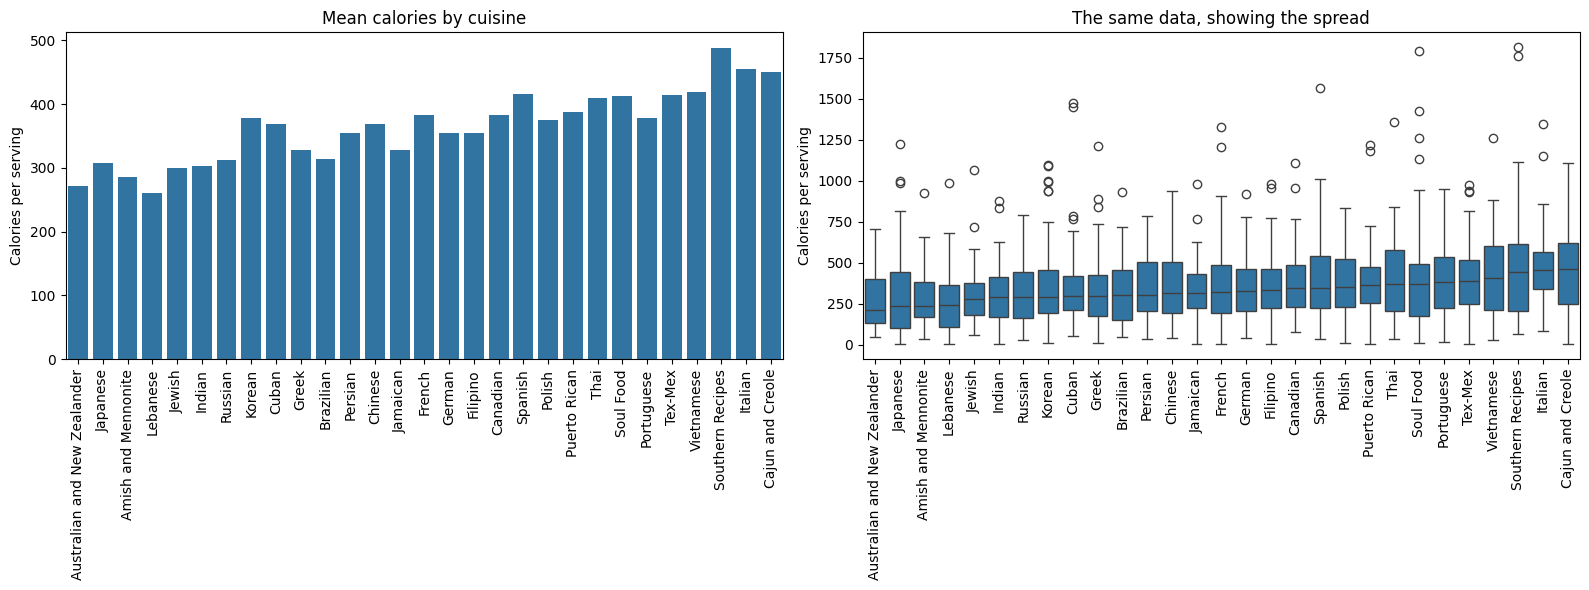

In [8]:
# Same data, two charts: group means, then the spread those means hide.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
order = plot_df.groupby('country')['calories'].median().sort_values().index

sns.barplot(data=plot_df, x='country', y='calories', order=order,
            errorbar=None, ax=axes[0])
axes[0].set_title('Mean calories by cuisine')

sns.boxplot(data=plot_df, x='country', y='calories', order=order, ax=axes[1])
axes[1].set_title('The same data, showing the spread')

for ax in axes:
    ax.tick_params(axis='x', rotation=90)
    ax.set_xlabel(''); ax.set_ylabel('Calories per serving')
plt.tight_layout()

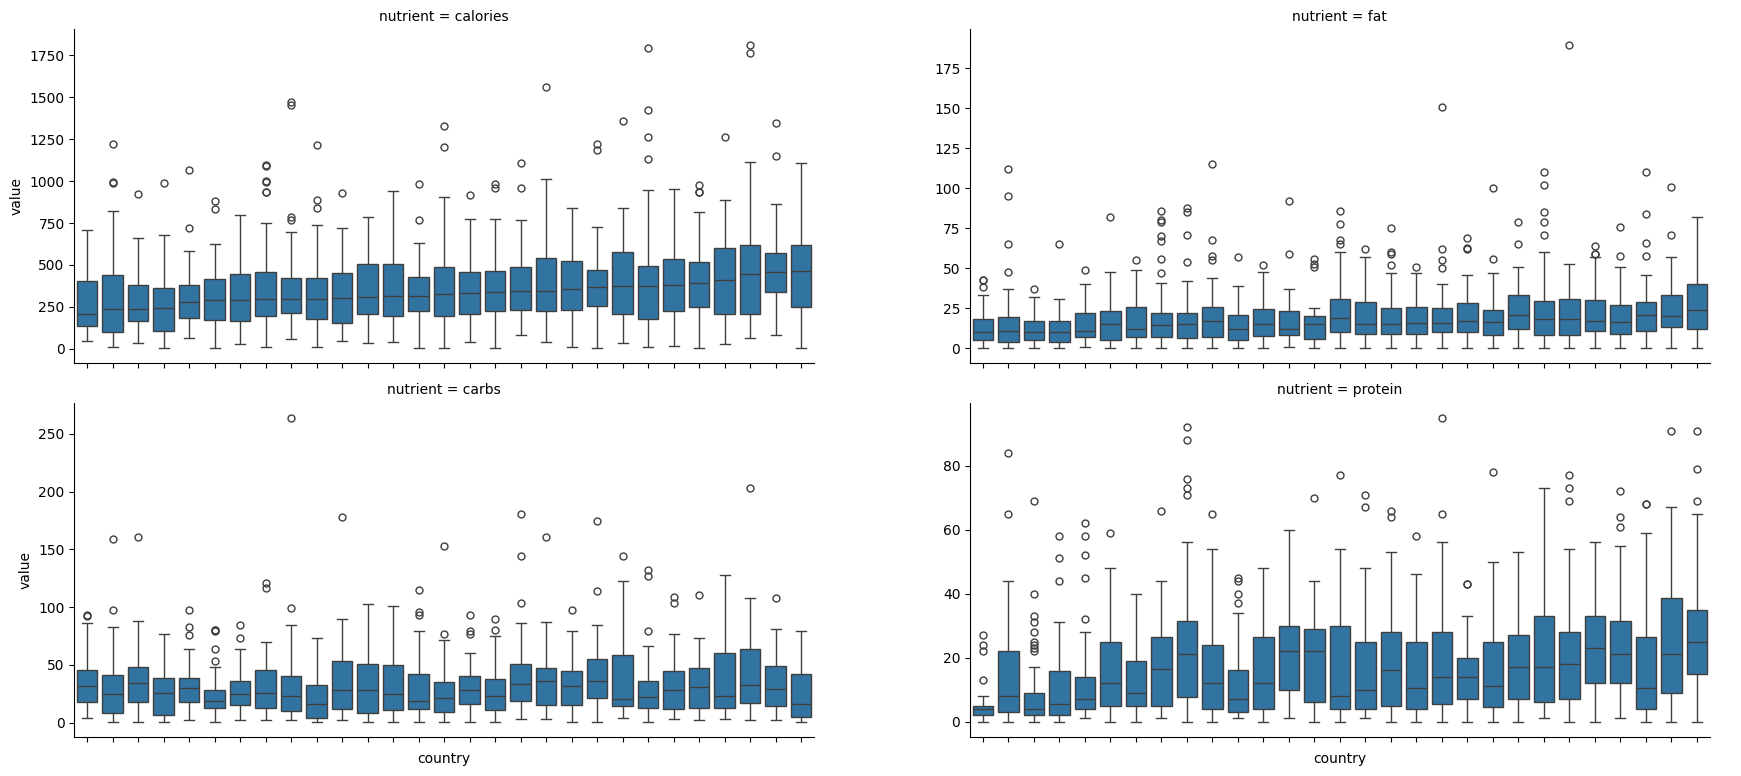

In [9]:
# Reshape so all four nutrients can be shown side by side.
long_df = plot_df.melt(id_vars='country',
                       value_vars=['calories','fat','carbs','protein'],
                       var_name='nutrient', value_name='value')

g = sns.catplot(data=long_df, x='country', y='value', col='nutrient',
                kind='box', col_wrap=2, sharey=False, height=4, aspect=2.2,
                order=order)
g.set_xticklabels(rotation=90)

**Section Takeaway**: At this point, I started to realize that going by country is going to be very hard to visualize. So, I decided to group countries by region instead. The next section explores how we arrived at that conclusion.

**Section Takeaway**:

# Exploring By Geographic Region

In [10]:
# Map each cuisine to a broader culinary region.
CUISINE_REGION = {
    'Chinese':'East Asian', 'Japanese':'East Asian', 'Korean':'East Asian',
    'Filipino':'Southeast Asian', 'Thai':'Southeast Asian',
    'Vietnamese':'Southeast Asian', 'Malaysian':'Southeast Asian',
    'Indonesian':'Southeast Asian',
    'Indian':'South Asian', 'Pakistani':'South Asian', 'Bangladeshi':'South Asian',
    'Lebanese':'Middle Eastern', 'Persian':'Middle Eastern',
    'Turkish':'Middle Eastern', 'Israeli':'Middle Eastern',
    'Brazilian':'Latin American', 'Cuban':'Latin American',
    'Puerto Rican':'Latin American', 'Jamaican':'Latin American',
    'Peruvian':'Latin American', 'Argentinian':'Latin American',
    'Chilean':'Latin American', 'Colombian':'Latin American',
    'Soul Food':'US Regional', 'Cajun and Creole':'US Regional',
    'Southern Recipes':'US Regional', 'Amish and Mennonite':'US Regional',
    'Tex-Mex':'US Regional',
    'German':'Central European', 'Austrian':'Central European',
    'Swiss':'Central European', 'Dutch':'Central European',
    'Belgian':'Central European',
    'Russian':'Eastern European', 'Polish':'Eastern European',
    'Scandinavian':'Nordic', 'Danish':'Nordic', 'Swedish':'Nordic',
    'Norwegian':'Nordic', 'Finnish':'Nordic',
    'Greek':'Mediterranean', 'Spanish':'Mediterranean', 'Portuguese':'Mediterranean',
    'Italian':'Italian', 'French':'French', 'Jewish':'Jewish',
    'Canadian':'Anglo', 'Australian and New Zealander':'Anglo',
    'South African':'South African',
}

desc_df['region'] = desc_df['country'].map(CUISINE_REGION)

# Anything unmapped would silently vanish from every chart below.
print("unmapped:", desc_df.loc[desc_df['region'].isna(), 'country'].unique())

unmapped: []


In [11]:
# How many recipes does each region have?
region_counts = desc_df['region'].value_counts()
print(region_counts)

region
Latin American      336
US Regional         292
Southeast Asian     238
East Asian          184
Mediterranean       176
Middle Eastern      155
Nordic              146
Anglo               132
Eastern European    126
Central European    122
South Asian         102
French               65
Italian              64
Jewish               61
South African        19
Name: count, dtype: int64


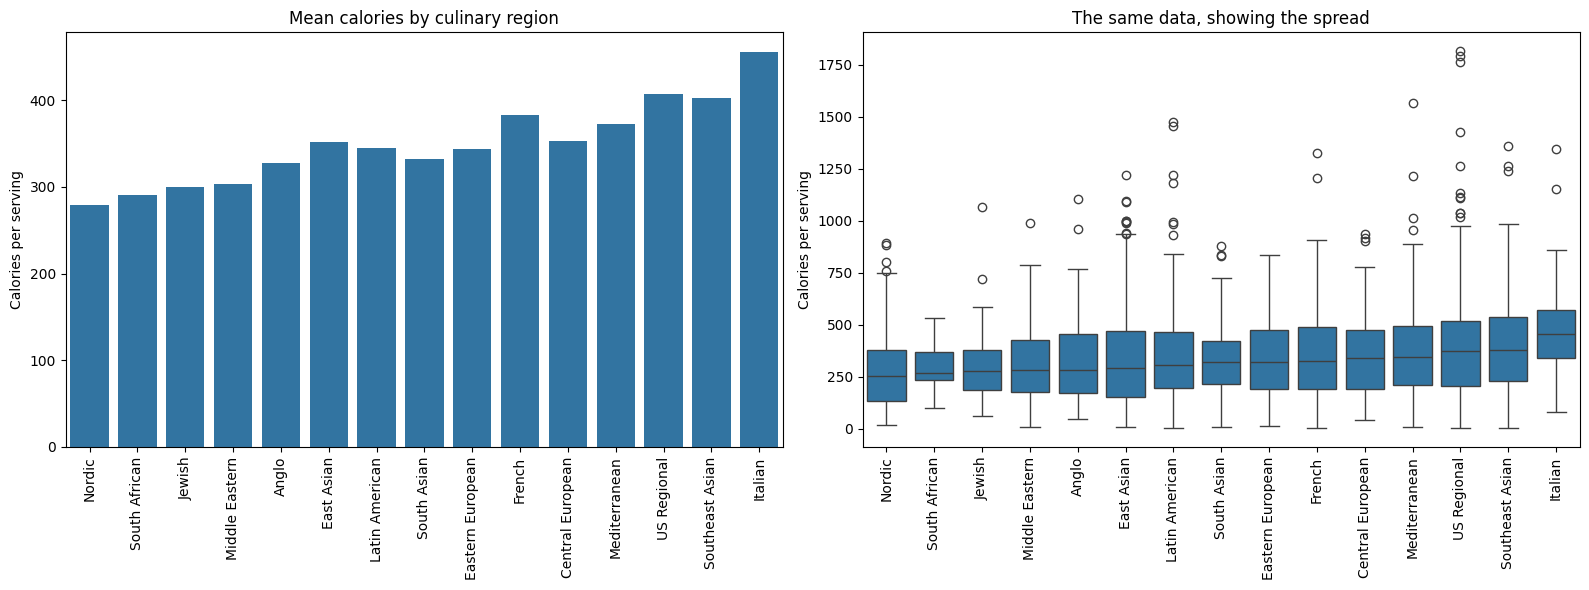

In [12]:
# Group means, then the spread those means hide.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
region_order = desc_df.groupby('region')['calories'].median().sort_values().index

sns.barplot(data=desc_df, x='region', y='calories', order=region_order,
            errorbar=None, ax=axes[0])
axes[0].set_title('Mean calories by culinary region')

sns.boxplot(data=desc_df, x='region', y='calories', order=region_order, ax=axes[1])
axes[1].set_title('The same data, showing the spread')

for ax in axes:
    ax.tick_params(axis='x', rotation=90)
    ax.set_xlabel(''); ax.set_ylabel('Calories per serving')
plt.tight_layout()

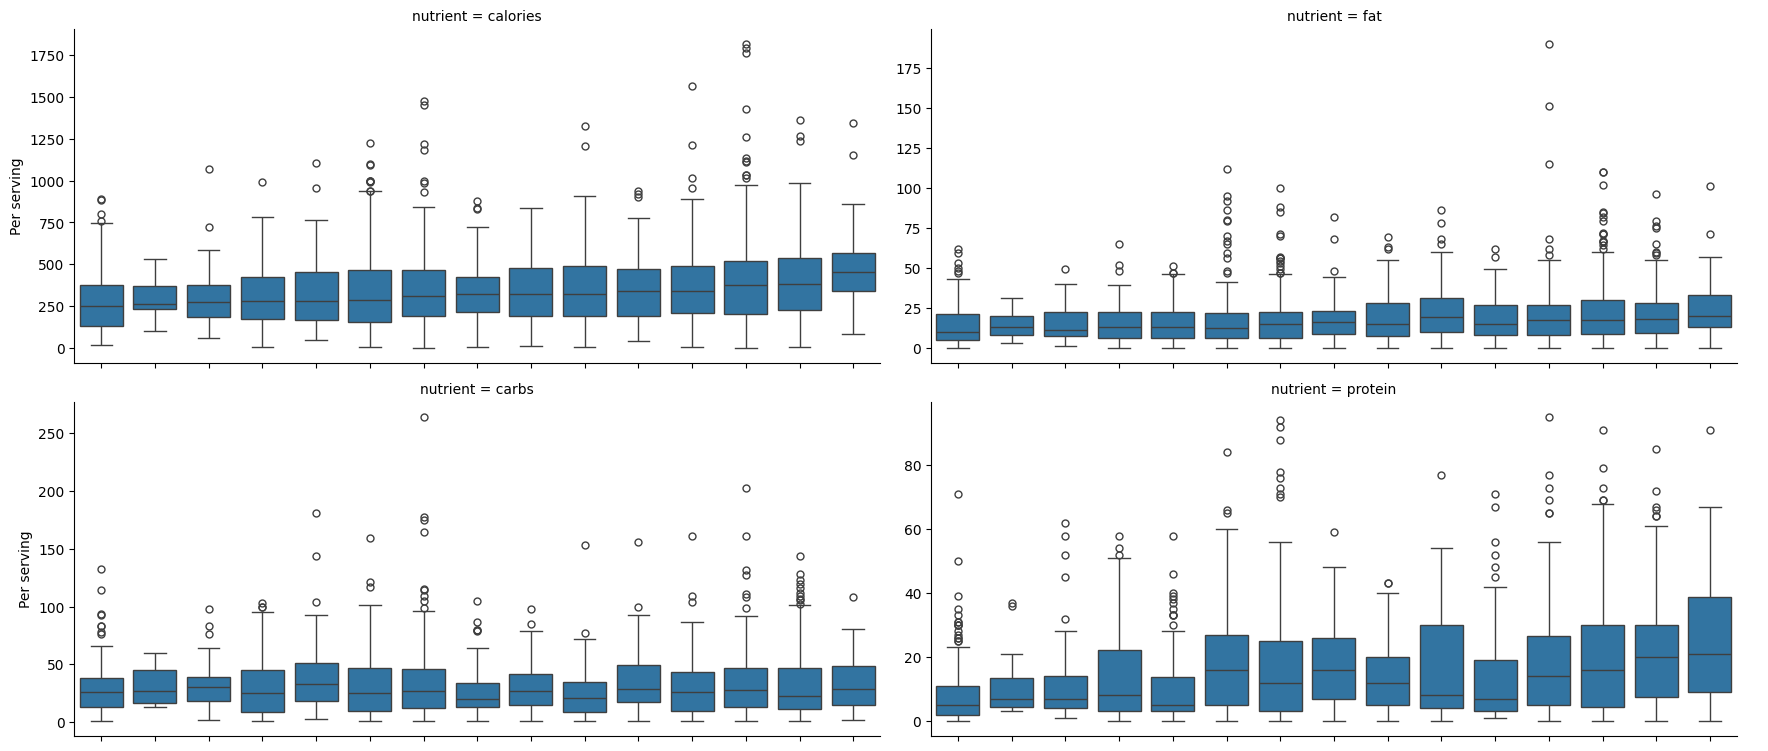

In [13]:
# Reshape so all four nutrients can be shown side by side.
long_region = desc_df.melt(id_vars='region',
                           value_vars=['calories','fat','carbs','protein'],
                           var_name='nutrient', value_name='value')

g = sns.catplot(data=long_region, x='region', y='value', col='nutrient',
                kind='box', col_wrap=2, sharey=False, height=4, aspect=2.2,
                order=region_order)
g.set_xticklabels(rotation=90)
g.set_axis_labels('', 'Per serving')

In [14]:
# What share of each recipe's calories comes from each macronutrient?
desc_df['pct_fat']     = desc_df['fat']     * 9 / desc_df['calories'] * 100
desc_df['pct_carbs']   = desc_df['carbs']   * 4 / desc_df['calories'] * 100
desc_df['pct_protein'] = desc_df['protein'] * 4 / desc_df['calories'] * 100

Text(0.5, 1.0, 'Nutritional signature of each culinary region')

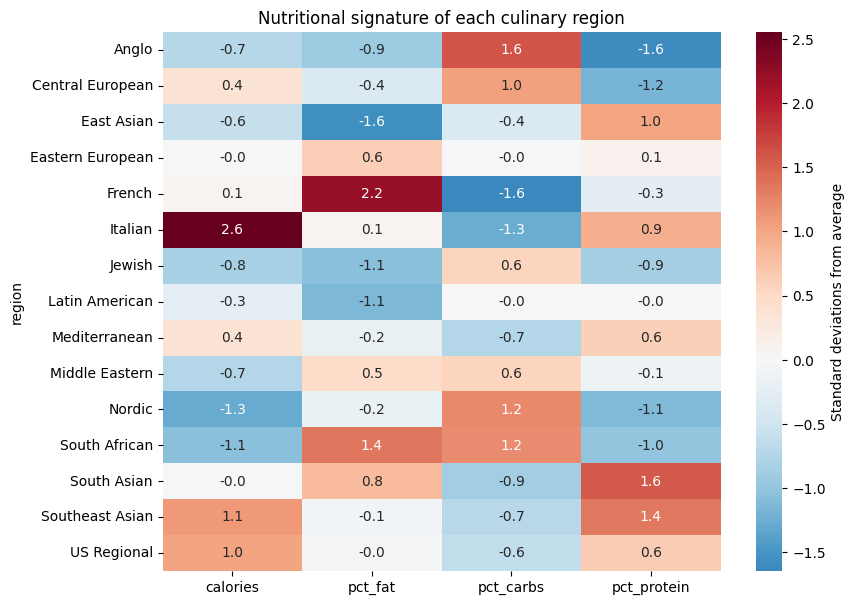

In [15]:
# Each region's nutritional signature, in standard deviations from the overall average.
cols = ['calories','pct_fat','pct_carbs','pct_protein']
z = desc_df.groupby('region')[cols].median()
z = (z - z.mean()) / z.std()

plt.figure(figsize=(9, 7))
sns.heatmap(z, cmap='RdBu_r', center=0, annot=True, fmt='.1f',
            cbar_kws={'label': 'Standard deviations from average'})
plt.title('Nutritional signature of each culinary region')

This heatmap tells a lot of the story. From this we can begin to see the similarities regions have in their nutrient makeup.

**Section Takeaway**:

# Visual Analysis by Region

Text(0.5, 1.0, 'Do regions trace different paths, or the same one?')

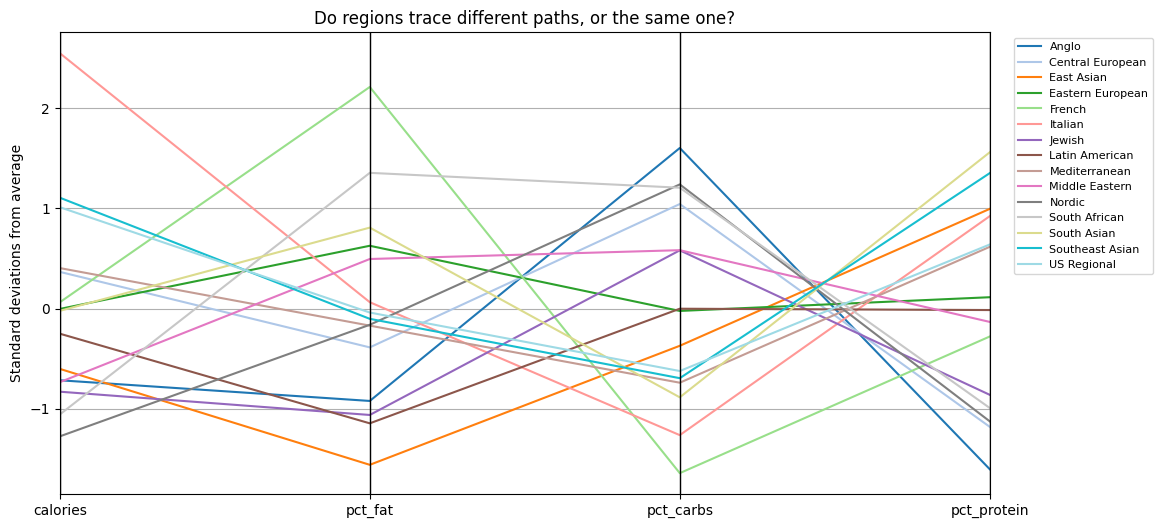

In [16]:
from pandas.plotting import parallel_coordinates

prof = z.reset_index()
plt.figure(figsize=(12, 6))
parallel_coordinates(prof, 'region', colormap='tab20')
plt.ylabel('Standard deviations from average')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.title('Do regions trace different paths, or the same one?')

This is a very ugly visual. However, you can begin to detect patterns and similarities between groups. We'll explore those next.

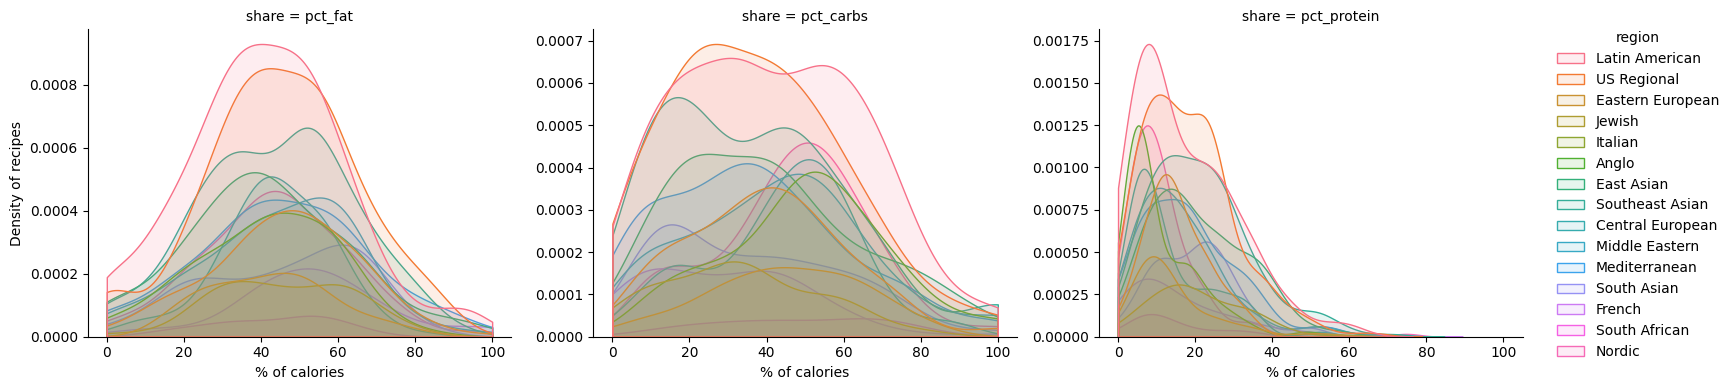

In [17]:
# How much do regions actually overlap on the nutrient share?
long_sel = desc_df.melt(id_vars='region',
                    value_vars=['pct_fat', 'pct_carbs', 'pct_protein'],
                    var_name='share', value_name='value')

g = sns.displot(data=long_sel, x='value', hue='region', col='share',
                kind='kde', fill=True, alpha=0.12, clip=(0, 100),
                height=4, aspect=1.3, facet_kws={'sharey': False})
g.set_axis_labels('% of calories', 'Density of recipes')

Also very ugly graphs. Again you can see the most similar countries and groups of countries as they tend to move together. There are 2 major groups that appear to jump out: northern european (Anglo, Central European, Nordic) and comfort foods (US Regional, Mediterranean, Southeast Asian). We'll isolate the rest of the visual analysis on those regions to explore how they are similar.

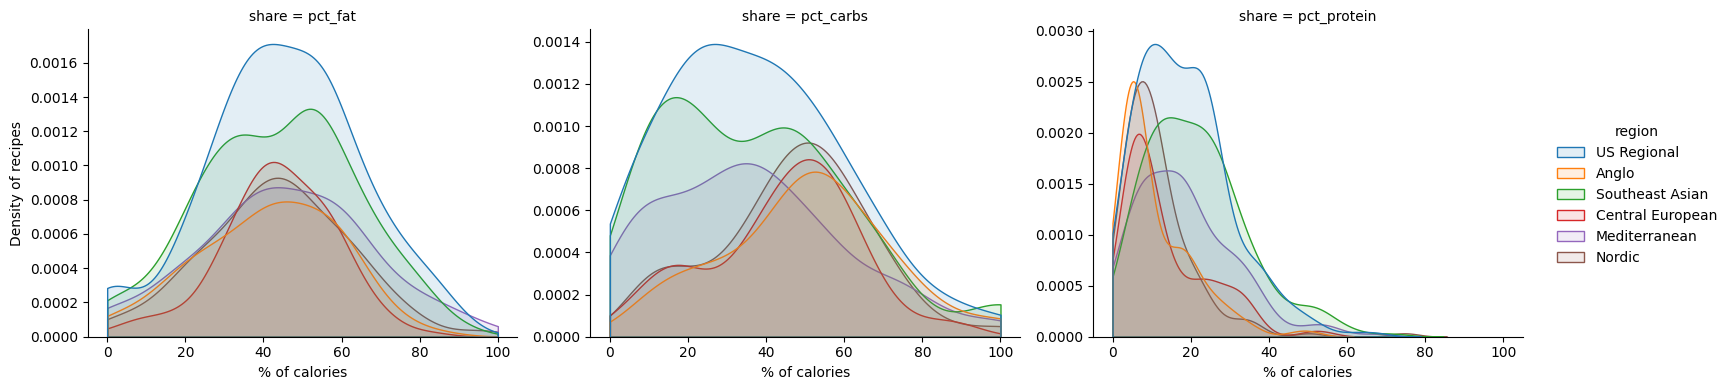

In [18]:
# The same five regions, across all three macronutrient shares.
similar = ['Anglo', 'Central European', 'Nordic', 'US Regional', 'Mediterranean', 'Southeast Asian']

sel = desc_df[desc_df.region.isin(similar)]
long_sel = sel.melt(id_vars='region',
                    value_vars=['pct_fat', 'pct_carbs', 'pct_protein'],
                    var_name='share', value_name='value')

g = sns.displot(data=long_sel, x='value', hue='region', col='share',
                kind='kde', fill=True, alpha=0.12, clip=(0, 100),
                height=4, aspect=1.3, facet_kws={'sharey': False})
g.set_axis_labels('% of calories', 'Density of recipes')

From this, we can clearly see there are distinct makeups between regions that overlap and imitate eachother.

In [19]:
# The six regions shown in every figure in this section.
FOCUS = ['Anglo', 'Nordic', 'Central European', 'Southeast Asian',
         'US Regional', 'Mediterranean']

focus_df = desc_df[desc_df.region.isin(FOCUS)].copy()
focus_order = focus_df.groupby('region')['calories'].median().sort_values().index

print(focus_df['region'].value_counts())

region
US Regional         292
Southeast Asian     238
Mediterranean       176
Nordic              146
Anglo               132
Central European    122
Name: count, dtype: int64


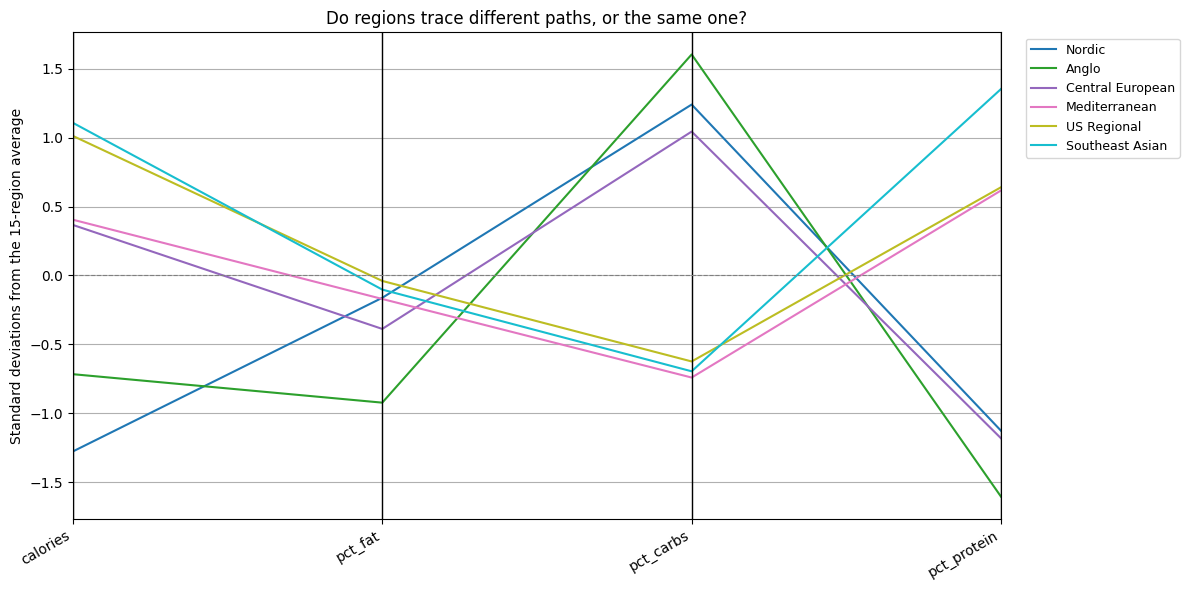

In [20]:
# Seven focus regions, still scored against all 15 so zero keeps its meaning.
col_order = ['calories', 'pct_fat', 'pct_carbs', 'pct_protein']
prof = z.loc[focus_order, col_order].reset_index()

plt.figure(figsize=(12, 6))
parallel_coordinates(prof, 'region', colormap='tab10')
plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.ylabel('Standard deviations from the 15-region average')
plt.xticks(rotation=30, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.title('Do regions trace different paths, or the same one?')
plt.tight_layout()

This is the simplified version of the same chart we looked at earlier. This graph shows how the 2 groups we described earlier (northern european and comfort food) "move" together. The up and down for the northern group and the down and up for the comfort regions.

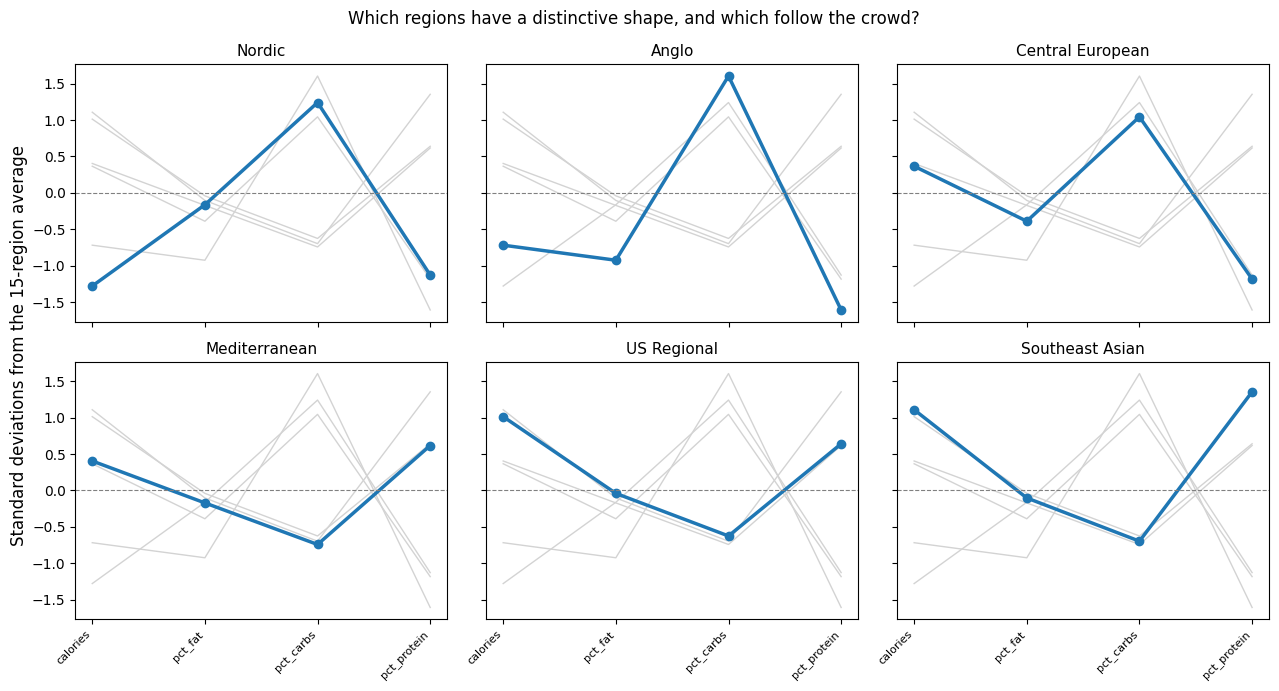

In [21]:
# One panel per region, with the other six ghosted behind for comparison.
col_order = ['calories', 'pct_fat', 'pct_carbs', 'pct_protein']
sub = z.loc[focus_order, col_order]
xs = range(len(col_order))

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True, sharex=True)
for ax, region in zip(axes.flat, focus_order):
    for other in focus_order:                      # ghost lines
        ax.plot(xs, sub.loc[other], color='lightgrey', linewidth=1)
    ax.plot(xs, sub.loc[region], color='tab:blue', linewidth=2.5, marker='o')
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    ax.set_title(region, fontsize=11)
    ax.set_xticks(list(xs))
    ax.set_xticklabels(col_order, rotation=45, ha='right', fontsize=8)

fig.supylabel('Standard deviations from the 15-region average')
fig.suptitle('Which regions have a distinctive shape, and which follow the crowd?')
plt.tight_layout()

The same visual as above but isolating each region to appreciate the full shape.

**Section Takeaway**:

# Notched Box Plot Analysis

In my first pass of notched box plots, I noticed there were a lot of minimum 0 calorie "meals." I investigated and found that there were blends and custom sauces that were included. I decided to remove those so we're looking at food dished only.

In [22]:
# Spice blends and seasonings are not dishes. Exclude them from the profile analysis.
desc_df['is_dish'] = desc_df['calories'] >= 50
print(f"{(~desc_df.is_dish).sum()} non-dish rows excluded")
print(desc_df.loc[~desc_df.is_dish, 'name'].head(20).tolist())

# Check which cuisines lose the most, so the exclusion is not silently regional.
print(desc_df.groupby('region')['is_dish'].agg(['mean', 'size']).round(3))

dish_df = desc_df[desc_df.is_dish].copy()

116 non-dish rows excluded
['Freddo Cappuccino', 'Swedish Glogg', 'Ekmek Turkish Bread', 'Freddo Espresso', 'Copycat Din Tai Fung Cucumber Salad', 'Crispitos', 'Game Day Sangria', 'Herbs de Provence', 'Best Hummus', 'White Peach Sangria', 'Indian Spiced Onions', 'Blackened Seasoning Mix', 'Fried Kimchi', 'Easy Mediterranean Baked Chicken Breast', 'Stir-Fried Mushrooms with Baby Corn', 'Homemade Pickled Ginger (Gari)', 'Cuban Mojito', 'Old-Fashioned Swedish Glögg', 'Homemade Sauerkraut', 'Atchara (Filipino Pickled Red Cabbage)']
                   mean  size
region                       
Anglo             0.985   132
Central European  0.959   122
East Asian        0.935   184
Eastern European  0.976   126
French            0.985    65
Italian           0.969    64
Jewish            1.000    61
Latin American    0.932   336
Mediterranean     0.909   176
Middle Eastern    0.910   155
Nordic            0.932   146
South African     1.000    19
South Asian       0.971   102
Southeast Asian 

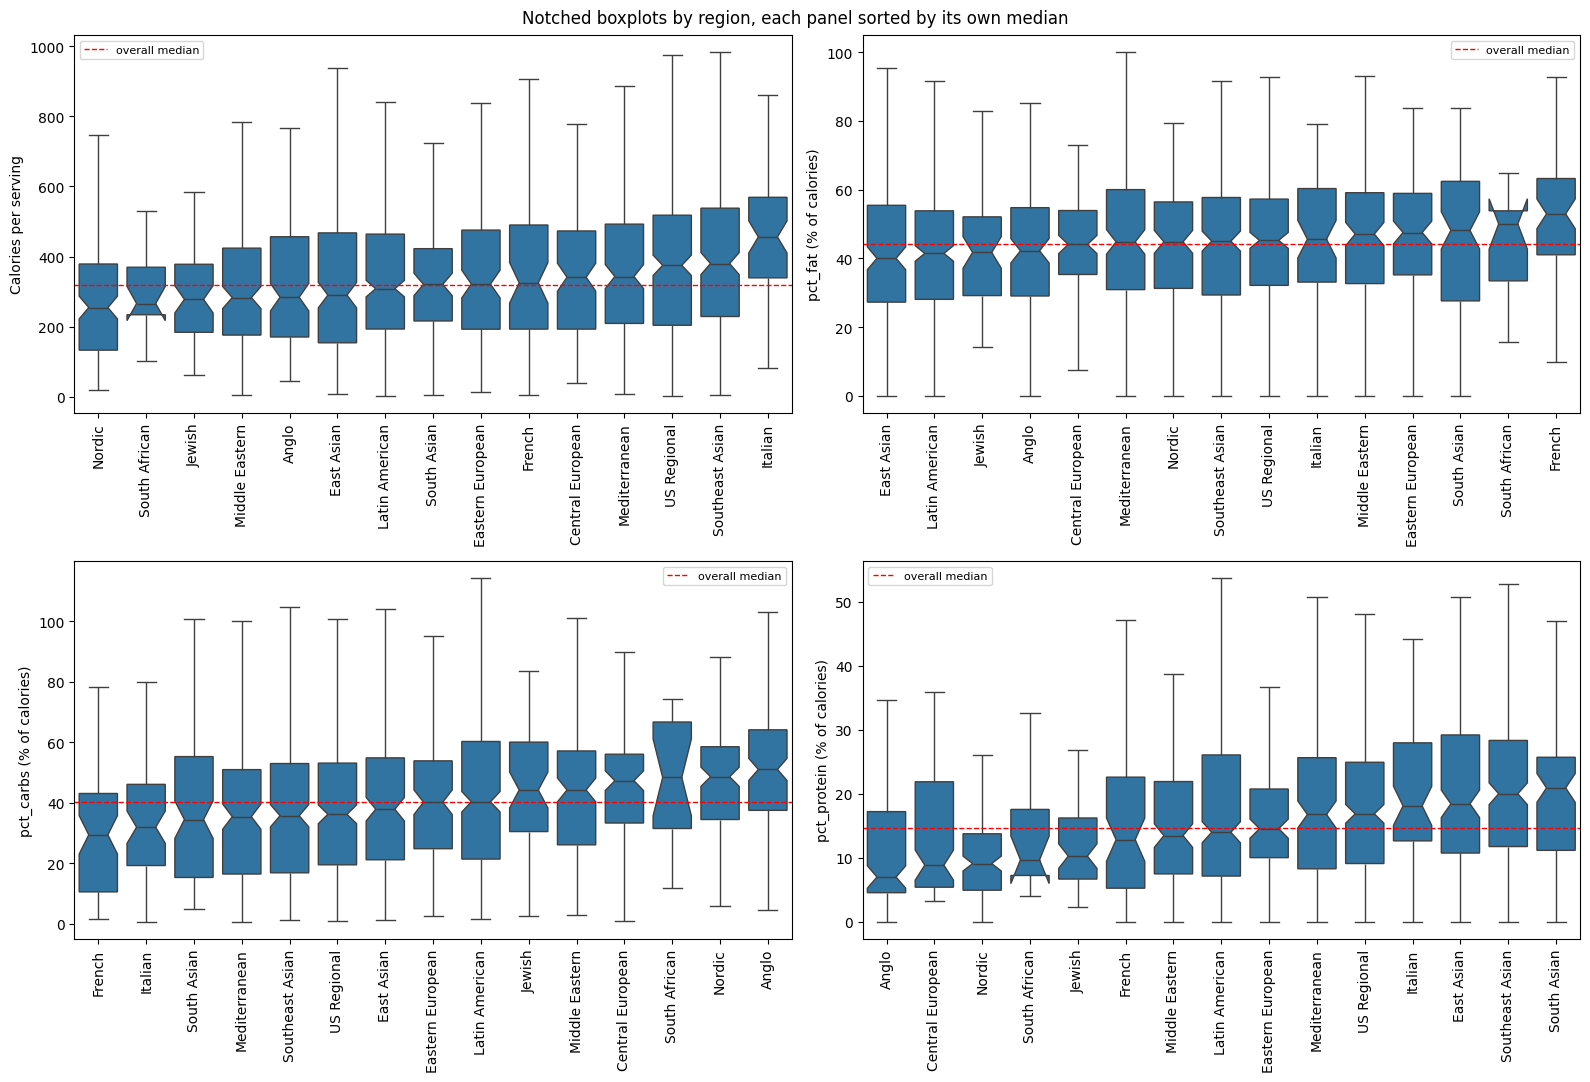

In [23]:
# Notched boxplots: do region medians differ, and does it matter given the spread?
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, col in zip(axes.flat, ['calories', 'pct_fat', 'pct_carbs', 'pct_protein']):
    panel_order = desc_df.groupby('region')[col].median().sort_values().index

    sns.boxplot(data=desc_df, x='region', y=col, order=panel_order,
                notch=True, showfliers=False, ax=ax)
    ax.axhline(desc_df[col].median(), color='red',
               linestyle='--', linewidth=1, label='overall median')
    ax.tick_params(axis='x', rotation=90)
    ax.set_xlabel('')
    ax.set_ylabel('Calories per serving' if col == 'calories'
                  else f'{col} (% of calories)')
    ax.legend(fontsize=8)

fig.suptitle('Notched boxplots by region, each panel sorted by its own median')
plt.tight_layout()

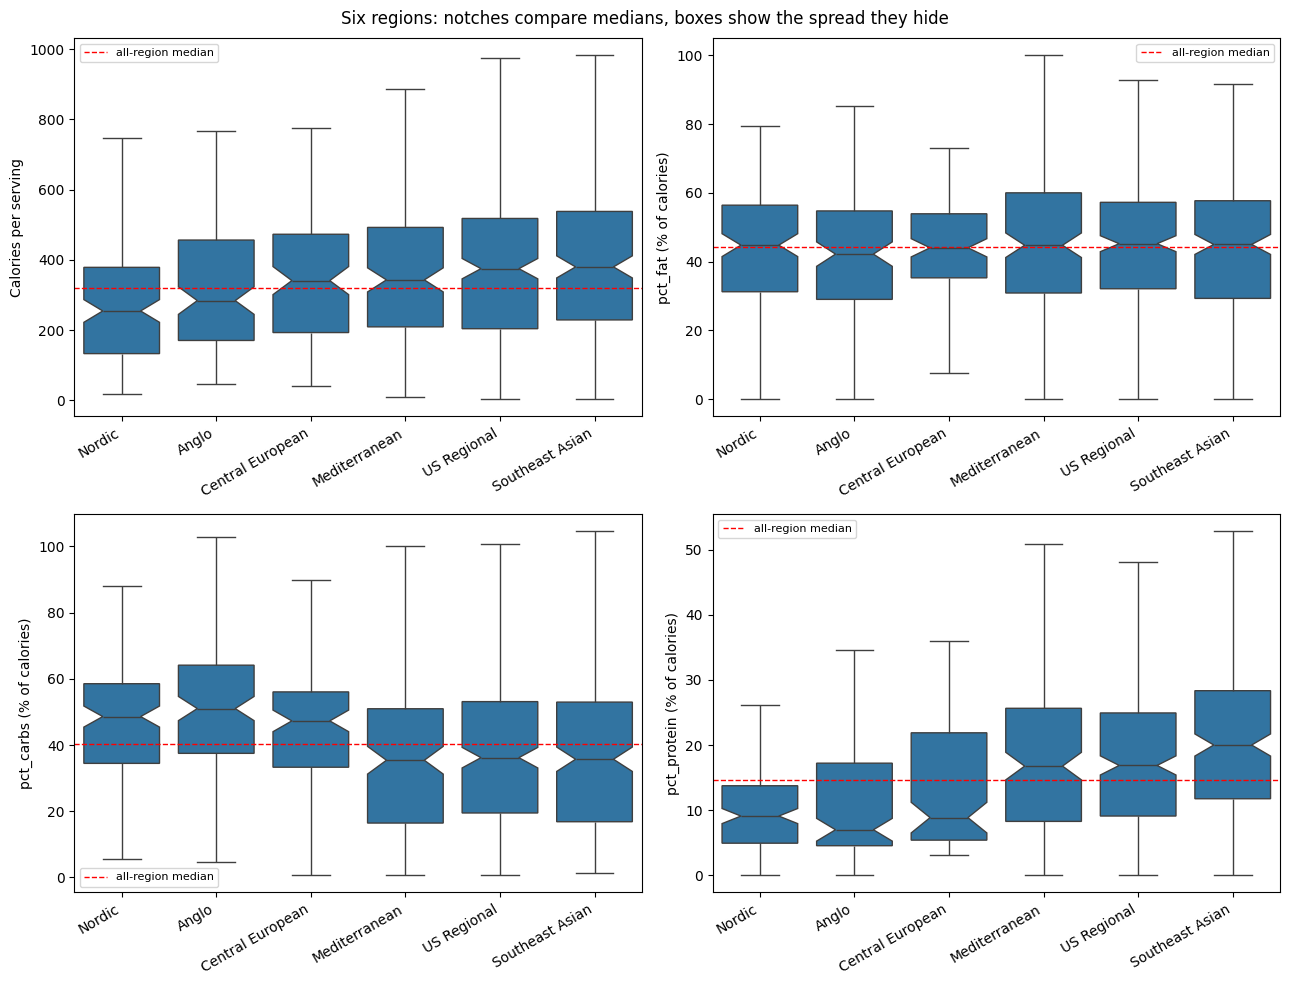

In [24]:
# Notched boxplots for the six focus regions, against the all-region median.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, col in zip(axes.flat, ['calories', 'pct_fat', 'pct_carbs', 'pct_protein']):
    sns.boxplot(data=focus_df, x='region', y=col, order=focus_order,
                notch=True, showfliers=False, ax=ax)
    ax.axhline(desc_df[col].median(), color='red',
               linestyle='--', linewidth=1, label='all-region median')
    ax.tick_params(axis='x', rotation=30)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')
    ax.set_xlabel('')
    ax.set_ylabel('Calories per serving' if col == 'calories'
                  else f'{col} (% of calories)')
    ax.legend(fontsize=8)

fig.suptitle('Six regions: notches compare medians, boxes show the spread they hide')
plt.tight_layout()

**Section Takeaway**:

# Final Reflection and Results

# Additional Visual Analysis

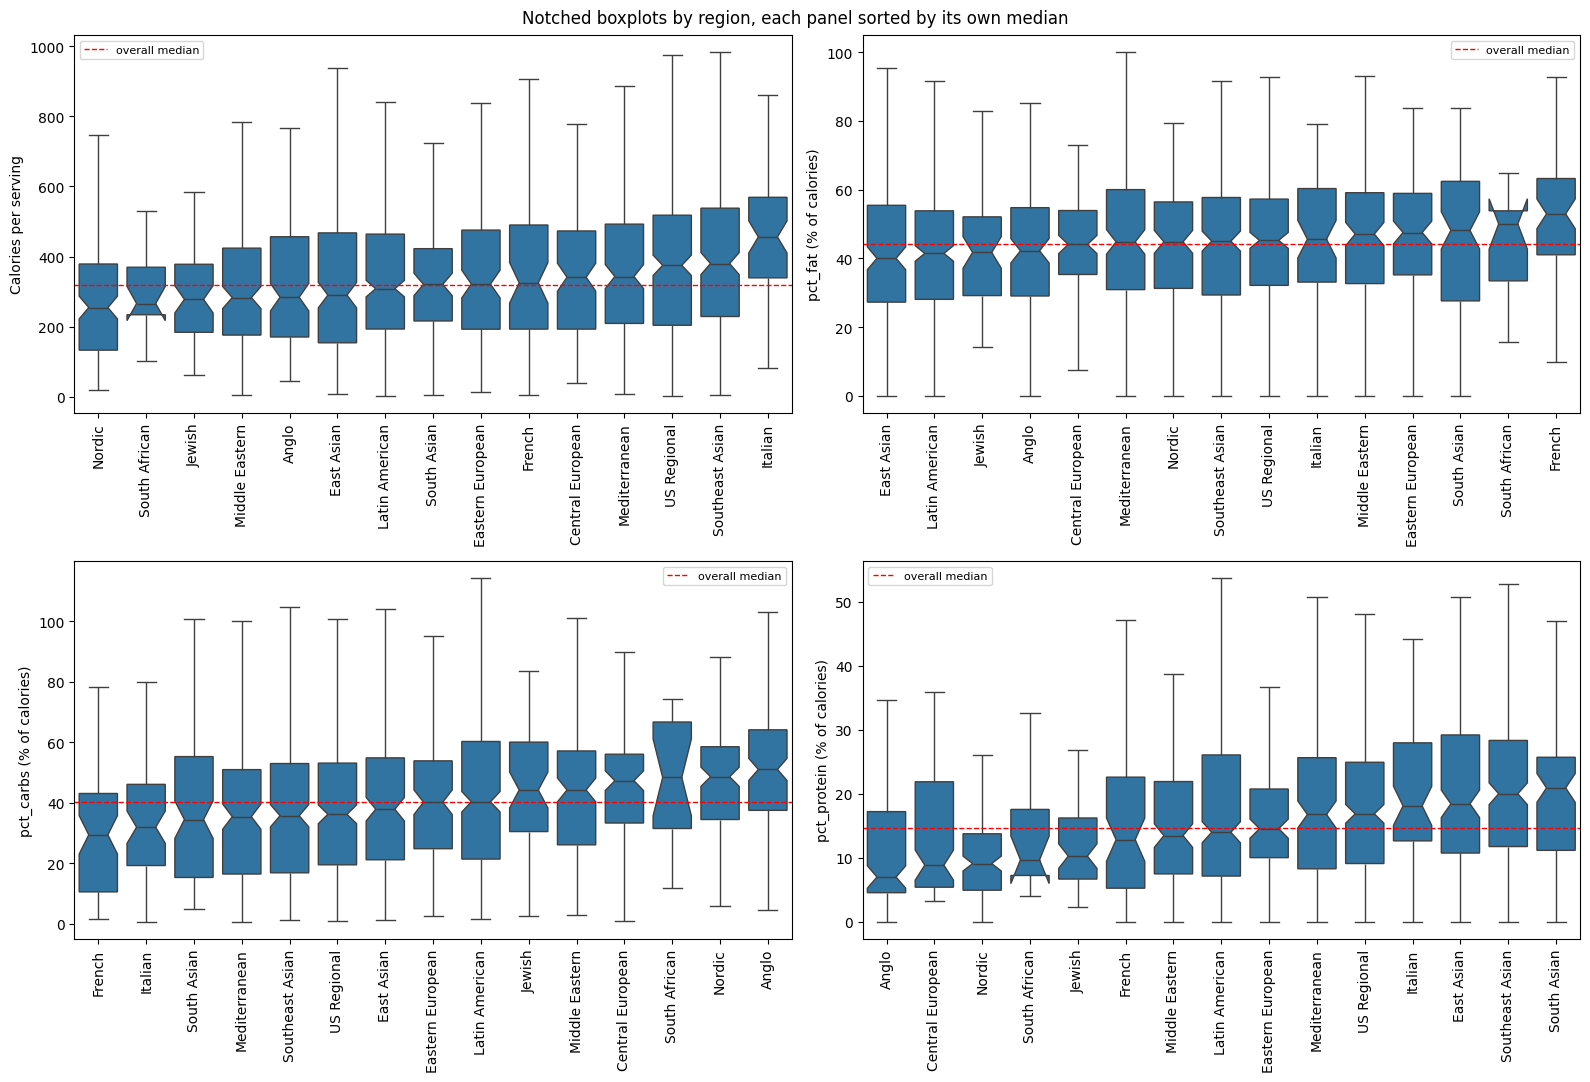

In [25]:
# Notched boxplots: do region medians differ, and does it matter given the spread?
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, col in zip(axes.flat, ['calories', 'pct_fat', 'pct_carbs', 'pct_protein']):
    panel_order = desc_df.groupby('region')[col].median().sort_values().index

    sns.boxplot(data=desc_df, x='region', y=col, order=panel_order,
                notch=True, showfliers=False, ax=ax)
    ax.axhline(desc_df[col].median(), color='red',
               linestyle='--', linewidth=1, label='overall median')
    ax.tick_params(axis='x', rotation=90)
    ax.set_xlabel('')
    ax.set_ylabel('Calories per serving' if col == 'calories'
                  else f'{col} (% of calories)')
    ax.legend(fontsize=8)

fig.suptitle('Notched boxplots by region, each panel sorted by its own median')
plt.tight_layout()

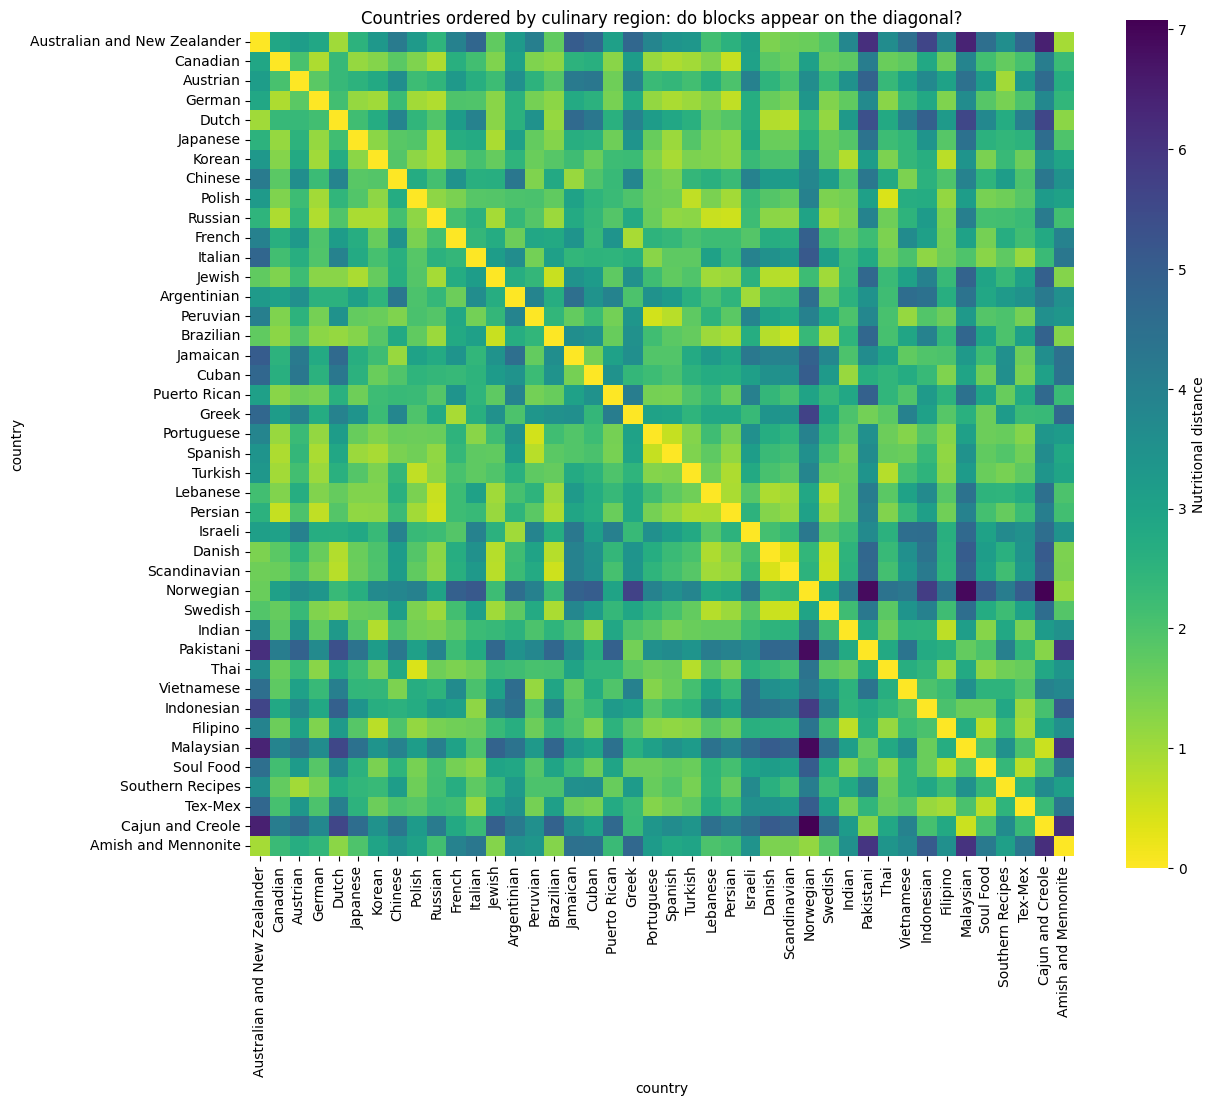

In [27]:
# Each country's nutritional signature, standardized across all countries.
cols = ['calories', 'pct_fat', 'pct_carbs', 'pct_protein']
big_countries = dish_df['country'].value_counts()
big_countries = big_countries[big_countries >= 20].index

zc = dish_df[dish_df.country.isin(big_countries)].groupby('country')[cols].median()
zc = (zc - zc.mean()) / zc.std()
zc['region'] = zc.index.map(CUISINE_REGION)

# Are countries closer to their own region's members than to outsiders?
from scipy.spatial.distance import pdist, squareform

ordered = zc.sort_values('region').index          # group members adjacent
D = pd.DataFrame(squareform(pdist(zc.loc[ordered, cols])),
                 index=ordered, columns=ordered)

plt.figure(figsize=(13, 11))
sns.heatmap(D, cmap='viridis_r', square=True,
            cbar_kws={'label': 'Nutritional distance'})
plt.title('Countries ordered by culinary region: do blocks appear on the diagonal?')
plt.tight_layout()